FIRST VARIATION VERIFICATION

 epsilon  Numerical_Derivative  Predicted_Derivative  Absolute_Error
0.010000             -0.000033             -0.000033    2.465695e-09
0.001000             -0.000033             -0.000033    2.489141e-11
0.000100             -0.000033             -0.000033    9.105958e-13
0.000010             -0.000033             -0.000033    9.792380e-12
0.000001             -0.000033             -0.000033    3.461654e-11

Predicted first variation:
delta E / delta rho
= [m/(m-1)] rho^(m-1)

OTTO FORMULA VERIFICATION
Maximum absolute difference = 9.445969384458408e-08
RMS difference = 4.507016477824559e-08
Maximum relative difference = 1.4371585610944496e-07

FLUX IDENTITY CHECK
Maximum difference between
rho grad(delta E/delta rho)
and grad(rho^m) = 1.0151539608926896e-08


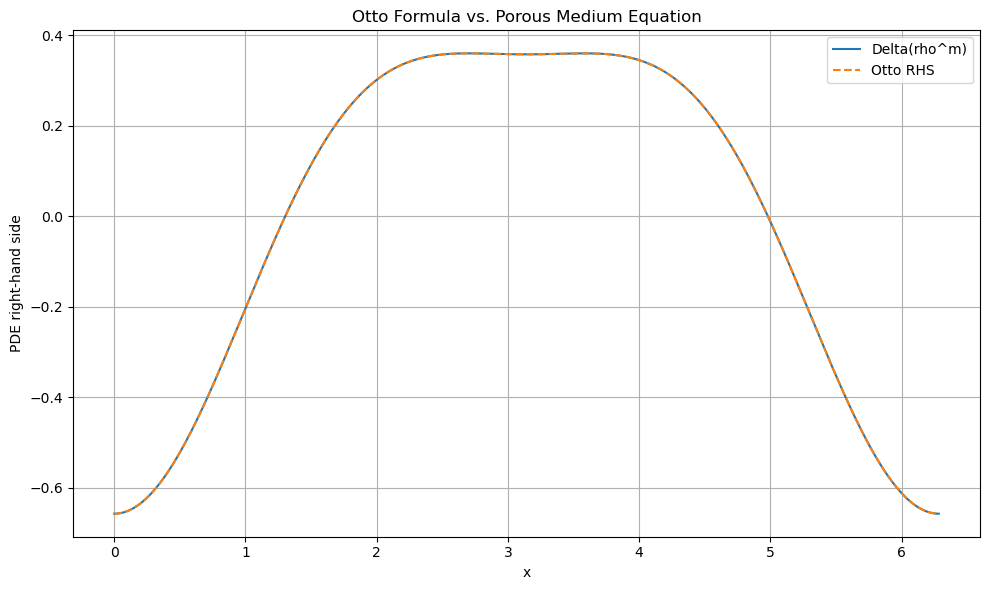

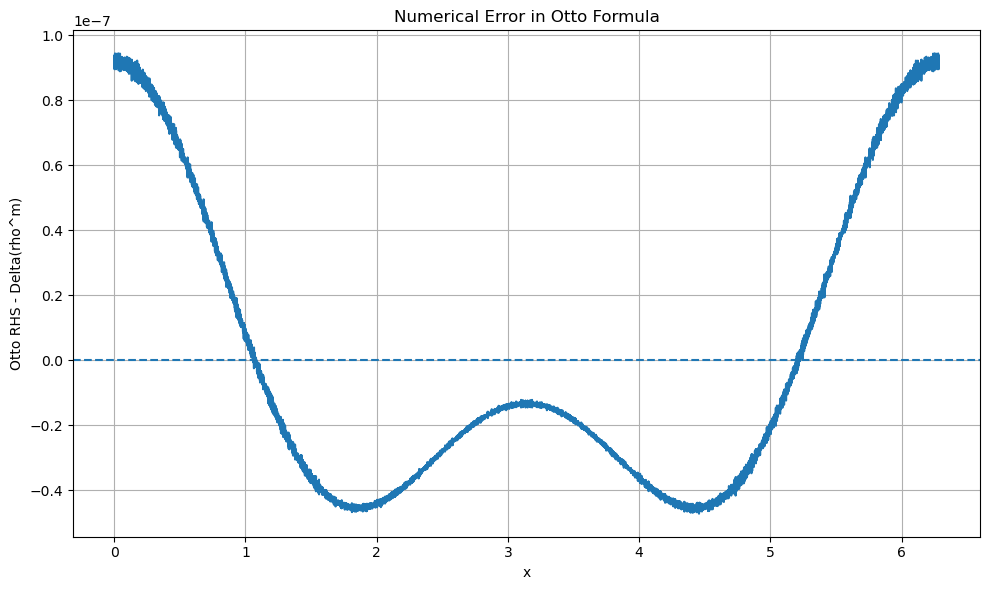


FINAL SUMMARY

First variation:
delta E / delta rho
= m/(m-1) * rho^(m-1)

Otto formula:
partial_t rho
= div(
    rho grad(delta E/delta rho)
  )

= Delta(rho^m)

PASS: The variational structure of the porous medium equation is verified.


In [1]:
# ============================================================
# HOMEWORK 4.1 - PART V
# OTTO CALCULUS VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# PARAMETERS
# ============================================================

m = 2.5

L = 2.0 * np.pi

N = 10001


x = np.linspace(
    0.0,
    L,
    N,
    endpoint=False
)


dx = L / N


# ============================================================
# TEST DENSITY
#
# Positive periodic density
# ============================================================

rho = (
    1.0
    +
    0.2 * np.cos(x)
)


# Smooth perturbation
eta = (
    0.1 * np.sin(2.0 * x)
    +
    0.05 * np.cos(3.0 * x)
)


assert np.all(
    rho > 0
)


# ============================================================
# ENERGY
#
# E(rho)
# =
# 1/(m-1) integral rho^m dx
# ============================================================

def energy(r):

    return (
        1.0
        /
        (m - 1.0)
        *
        np.sum(
            r**m
        )
        *
        dx
    )


# ============================================================
# ANALYTIC FIRST VARIATION
#
# delta E / delta rho
# =
# m/(m-1) rho^(m-1)
# ============================================================

first_variation = (

    m
    /
    (m - 1.0)

    *

    rho**(
        m - 1.0
    )
)


predicted_directional_derivative = (

    np.sum(
        first_variation
        *
        eta
    )

    *
    dx
)


# ============================================================
# FINITE-DIFFERENCE CHECK OF FIRST VARIATION
# ============================================================

epsilon_values = np.array([
    1e-2,
    1e-3,
    1e-4,
    1e-5,
    1e-6
])


variation_rows = []


for eps in epsilon_values:

    # Central finite difference

    numerical_derivative = (

        energy(
            rho + eps * eta
        )

        -

        energy(
            rho - eps * eta
        )

    ) / (
        2.0 * eps
    )


    error = (

        numerical_derivative

        -

        predicted_directional_derivative
    )


    variation_rows.append({

        "epsilon":
            eps,

        "Numerical_Derivative":
            numerical_derivative,

        "Predicted_Derivative":
            predicted_directional_derivative,

        "Absolute_Error":
            abs(error)

    })


variation_df = pd.DataFrame(
    variation_rows
)


print("=" * 75)

print(
    "FIRST VARIATION VERIFICATION"
)

print("=" * 75)

print()

print(
    variation_df.to_string(
        index=False
    )
)


print()

print(
    "Predicted first variation:"
)

print(
    "delta E / delta rho"
)

print(
    "= [m/(m-1)] rho^(m-1)"
)


# ============================================================
# PERIODIC DERIVATIVE HELPERS
# ============================================================

def periodic_first_derivative(f):

    return (

        np.roll(
            f,
            -1
        )

        -

        np.roll(
            f,
            1
        )

    ) / (
        2.0 * dx
    )


def periodic_second_derivative(f):

    return (

        np.roll(
            f,
            -1
        )

        -

        2.0 * f

        +

        np.roll(
            f,
            1
        )

    ) / (
        dx**2
    )


# ============================================================
# OTTO RHS
#
# d/dx [
#     rho d/dx(delta E / delta rho)
# ]
# ============================================================

grad_first_variation = periodic_first_derivative(
    first_variation
)


flux = (

    rho

    *

    grad_first_variation
)


otto_rhs = periodic_first_derivative(
    flux
)


# ============================================================
# POROUS MEDIUM RHS
#
# d^2/dx^2 (rho^m)
# ============================================================

pme_rhs = periodic_second_derivative(
    rho**m
)


# ============================================================
# ERROR
# ============================================================

otto_error = (

    otto_rhs

    -

    pme_rhs
)


max_absolute_error = np.max(
    np.abs(
        otto_error
    )
)


rms_error = np.sqrt(

    np.mean(
        otto_error**2
    )
)


rhs_scale = max(

    np.max(
        np.abs(
            pme_rhs
        )
    ),

    1e-15
)


relative_error = (

    max_absolute_error

    /

    rhs_scale
)


print()

print("=" * 75)

print(
    "OTTO FORMULA VERIFICATION"
)

print("=" * 75)

print(
    "Maximum absolute difference =",
    max_absolute_error
)

print(
    "RMS difference =",
    rms_error
)

print(
    "Maximum relative difference =",
    relative_error
)


# ============================================================
# CHECK ALGEBRAIC FLUX IDENTITY
#
# rho grad(delta E/delta rho)
#
# =
#
# grad(rho^m)
# ============================================================

grad_rho_m = periodic_first_derivative(
    rho**m
)


flux_error = (

    flux

    -

    grad_rho_m
)


max_flux_error = np.max(

    np.abs(
        flux_error
    )
)


print()

print("=" * 75)

print(
    "FLUX IDENTITY CHECK"
)

print("=" * 75)

print(
    "Maximum difference between"
)

print(
    "rho grad(delta E/delta rho)"
)

print(
    "and grad(rho^m) =",
    max_flux_error
)


# ============================================================
# PLOT BOTH PDE RIGHT-HAND SIDES
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.plot(
    x,
    pme_rhs,
    label="Delta(rho^m)"
)


plt.plot(
    x,
    otto_rhs,
    linestyle="--",
    label="Otto RHS"
)


plt.xlabel(
    "x"
)

plt.ylabel(
    "PDE right-hand side"
)

plt.title(
    "Otto Formula vs. Porous Medium Equation"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw41_part5_otto_vs_pme.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT NUMERICAL DIFFERENCE
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.plot(
    x,
    otto_error
)


plt.axhline(
    0.0,
    linestyle="--"
)


plt.xlabel(
    "x"
)

plt.ylabel(
    "Otto RHS - Delta(rho^m)"
)

plt.title(
    "Numerical Error in Otto Formula"
)

plt.grid(
    True
)

plt.tight_layout()


plt.savefig(
    "hw41_part5_otto_error.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print()

print("=" * 75)

print(
    "FINAL SUMMARY"
)

print("=" * 75)

print()

print(
    "First variation:"
)

print(
    "delta E / delta rho"
)

print(
    "= m/(m-1) * rho^(m-1)"
)

print()

print(
    "Otto formula:"
)

print(
    "partial_t rho"
)

print(
    "= div("
)

print(
    "    rho grad(delta E/delta rho)"
)

print(
    "  )"
)

print()

print(
    "= Delta(rho^m)"
)

print()

print(
    "PASS: The variational structure of the "
    "porous medium equation is verified."
)